In [1]:
'''
All Credits to John " https://zindi.africa/users/Johnowhitaker ", for his amazing starting kernel, and live video
to help us all.
'''

'\nAll Credits to John " https://zindi.africa/users/Johnowhitaker ", for his amazing starting kernel, and live video\nto help us all.\n'

In [2]:
## Run once to install:
# !pip install geopandas rasterio
# !pip install descartes
# !pip install fastai2
# !pip install tqdm
# !pip install efficientnet_pytorch

In [3]:
## For reproducible results.
## Results may still not be reproducible if different hardware config is used, or the package versions are changed
def random_seed(seed_value):
    import random 
    random.seed(seed_value) # Python
    import numpy as np
    np.random.seed(seed_value) # cpu vars
    import torch
    torch.manual_seed(seed_value) # cpu  vars
    
    if torch.cuda.is_available(): 
        torch.cuda.manual_seed(seed_value)
        torch.cuda.manual_seed_all(seed_value) # gpu vars
        torch.backends.cudnn.deterministic = True  #needed
        torch.backends.cudnn.benchmark = False

In [4]:
import pandas as pd
import numpy as np
import random
import geopandas as gpd
import rasterio
from PIL import Image
from matplotlib import pyplot as plt
%matplotlib inline

import gc

from sklearn.metrics import *
from sklearn.model_selection import StratifiedKFold
from tqdm import tqdm_notebook
import fastai2
from fastai2.vision.all import *

In [5]:
import fastai2.vision as fvs

In [6]:
from efficientnet_pytorch import EfficientNet

In [7]:
fvs.models.densenet169

<function torchvision.models.densenet.densenet169(pretrained=False, progress=True, **kwargs)>

In [8]:
df = pd.read_csv('Train.csv')
test = pd.read_csv('Test.csv')
df.sample(5)

,ID,LAT,LON,Label
4195,Z6Z28D5,-25.774,28.446,False
1149,9RLLQSF,-25.757,28.406,False
3946,WX58HMW,-25.704,28.434,True
2868,NS3Q4AQ,-25.700,28.407,False
4275,ZXCA9Q7,-25.739,28.425,True


In [9]:
# CHeck shape and number of True labels
df.shape, df.Label.sum()

((4281, 4), 1094)

In [10]:
# Check the extent
df.min(), df.max()

(ID       0059CI9
 LAT       -25.78
 LON        28.35
 Label      False
 dtype: object,
 ID       ZZ6LRO7
 LAT       -25.68
 LON        28.45
 Label       True
 dtype: object)

In [11]:
# Sample submission:
ss = pd.read_csv('SampleSubmission.csv')
ss.head(3)

,ID,Label
0,00MZGKU,0
1,015JA41,0
2,01POB64,0


In [12]:
 dataset = rasterio.open('2528C.tif') # We'll use rasterio for all raster operations

In [13]:
dataset.bounds # Check the geographoc bounds of this tile - notice that it covers all the training data.

BoundingBox(left=27.9999999999999, bottom=-25.999999999894882, right=28.4999999999999, top=-25.499999999894882)

In [14]:
# We can get information such as the number of bands and the band names. 
# In this case there are 3, for R, G and B channels
band_names = dataset.descriptions
n_bands = dataset.count
band_names, n_bands

((None, None, None), 3)

In [15]:
# # Load bands into RAM
red, green, blue = dataset.read(1), dataset.read(2), dataset.read(3)

In [16]:
W, H = 120, 120

In [17]:
# Get the image:
random_seed(19)
def get_x(ID):
    row = df.loc[df.ID == ID]
    lat, lon = row['LAT'].values[0], row['LON'].values[0]
    im = np.zeros((W, H, 3), np.uint8)
    row, col = dataset.index(lon, lat)
    for i, band in enumerate([red, green, blue]):
        im[:,:,i] = band[row-W//2: row+W//2, col-H//2:col+H//2]
    
    return im

# And the label
def get_y(ID):
    row = df.loc[df.ID == ID]
    return int(row['Label'].values[0])

# Get the list of Image IDS:
def get_im_ids(path):
    return df.ID.values

# And build the datablock
dblock = DataBlock(
    blocks=(ImageBlock, CategoryBlock),
    get_items=get_im_ids,
    get_x=get_x,
    get_y=get_y, 
    splitter=RandomSplitter(valid_pct=0.02),
    batch_tfms=aug_transforms(size=W, do_flip=True, flip_vert=True, max_rotate=180, max_lighting=0.6, p_lighting=0.12)
)
dls = dblock.dataloaders(Path(''), bs=32)
# dls.show_batch()

In [21]:
# Create the learner
random_seed(1)
learn = cnn_learner(dls, densenet201, metrics=[accuracy])

# Train
learn.fine_tune(5)

epoch,train_loss,valid_loss,accuracy,time
0,0.554709,0.372316,0.905882,00:51


epoch,train_loss,valid_loss,accuracy,time
0,0.281176,0.179137,0.952941,01:13
1,0.223841,0.162359,0.952941,01:13
2,0.172585,0.121630,0.964706,01:13
3,0.131936,0.093179,0.976471,01:13
4,0.115307,0.092077,0.976471,01:13


In [22]:
!ls *.tif

2528C.tif  2628C.tif  2930C.tif  2930D.tif


In [23]:
dataset = rasterio.open('2930D.tif')
red, green, blue = dataset.read(1), dataset.read(2), dataset.read(3)

In [24]:
test['Label'] = 0
df = test.copy()

In [71]:
random_seed(22)
idxs = test['ID'].values
tdl = learn.dls.test_dl(idxs, )
test_preds, test_labels = learn.tta(dl=tdl, n=11)

In [72]:
# test_preds, test_labels = learn.tta(ds_idx = df[:-test.shape[0]].index.tolist())

In [85]:
pd.Series(test_preds.numpy()[:, 1]).sort_values(ascending=False)[:20]

1441    0.995766
618     0.988717
479     0.981710
1916    0.981325
2483    0.980623
697     0.975255
1584    0.973956
1700    0.973809
272     0.972646
1854    0.964446
1632    0.963205
938     0.959416
1816    0.952865
2281    0.950122
71      0.949912
2515    0.947587
1570    0.943224
859     0.943021
2132    0.937394
477     0.936249
dtype: float32

In [86]:
pd.Series(test_preds.numpy()[:, 1]).round().value_counts(normalize=True)

0.0    0.891313
1.0    0.108687
dtype: float64

In [87]:
test['Label'] = [p[1] for p in test_preds.numpy()]
test.head()

,ID,LAT,LON,Label
0,00MZGKU,-29.8920,30.8575,0.016281
1,015JA41,-29.8905,30.8705,0.072573
2,01POB64,-29.9615,30.8950,0.096159
3,02125F8,-29.9660,30.8500,0.029790
4,03E8VFF,-29.9080,30.8760,0.042638


In [88]:
test['Label'].describe()

count    2613.000000
mean        0.165079
std         0.228406
min         0.000002
25%         0.012257
50%         0.056056
75%         0.227701
max         0.995766
Name: Label, dtype: float64

In [89]:
test['Label'] = np.clip(test['Label'], 0, 0.8)

In [90]:
test['Label'].round().value_counts(normalize=True)

0.0    0.891313
1.0    0.108687
Name: Label, dtype: float64

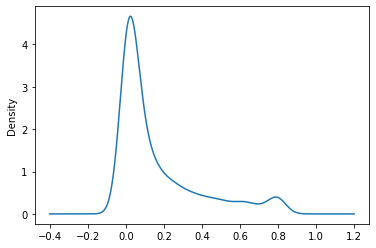

In [91]:
test['Label'].plot(kind='density')

In [92]:
# test[['ID', 'Label']].to_csv('outputs/sub_0.616.csv', index=False)
test[['ID', 'Label']].to_csv('sub_24.csv', index=False)

In [93]:
test.head()

,ID,LAT,LON,Label
0,00MZGKU,-29.8920,30.8575,0.016281
1,015JA41,-29.8905,30.8705,0.072573
2,01POB64,-29.9615,30.8950,0.096159
3,02125F8,-29.9660,30.8500,0.029790
4,03E8VFF,-29.9080,30.8760,0.042638
